## Step 1: Import libraries and load the cleaned dataset

In [153]:
# Data analysis
import pandas as pd
import numpy as np
# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
# Count genre labels
from collections import Counter
# Visualisation settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
%matplotlib inline
# Load the cleaned dataset
file_path = "../Data/Goodreads Books Cleaned.csv"
df = pd.read_csv(file_path)
# Display the first five records
display(df.head())

,bookId,title,author,description,genres,language,num_pages,num_ratings,num_reviews,avg_rating,rated_1,rated_2,rated_3,rated_4,rated_5
0,1,Harry Potter and the Half-Blood Prince,J.K. Rowling,The war against Voldemort is not going well; e...,"Art,Biography,Business,Children's,Christian,Cl...",English,652.0,2553909.0,41470.0,4.57,13147.0,29020.0,174312.0,608825.0,1728605.0
1,2,Harry Potter and the Order of the Phoenix,"J.K. Rowling,Mary Grandpré",There is a door at the end of a silent corrido...,"Art,Biography,Business,Children's,Christian,Cl...",English,870.0,2631427.0,44793.0,4.50,16236.0,41738.0,231438.0,665628.0,1676387.0
2,3,Harry Potter and the Sorcerer's Stone,"J.K. Rowling,Mary Grandpré",Harry Potter's life is miserable. His parents ...,"Art,Biography,Business,Children's,Christian,Cl...",English,309.0,7434783.0,117823.0,4.48,126344.0,147184.0,627803.0,1694206.0,4839246.0
3,4,Harry Potter and the Chamber of Secrets,J.K. Rowling,The Dursleys were so mean and hideous that sum...,"Art,Biography,Business,Children's,Christian,Cl...",English,352.0,2878196.0,55839.0,4.43,15623.0,55060.0,315917.0,787181.0,1704415.0
4,5,Harry Potter and the Prisoner of Azkaban,"J.K. Rowling,Mary Grandpré","For twelve long years, the dread fortress of A...","Art,Biography,Business,Children's,Christian,Cl...",English,435.0,2972519.0,58483.0,4.57,14124.0,29105.0,214151.0,701765.0,2013374.0


### Step 2: Understand the dataset

In [154]:
# Dataset dimensions
print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])
# Column names
print("Columns in the dataset:")
for column in df.columns:
    print("-", column)
# Data types and non-null values
df.info()
# Preview the first and last five records
display(df.head())
display(df.tail())

Dataset shape: (19941, 15)
Number of records: 19941
Number of columns: 15
Columns in the dataset:
- bookId
- title
- author
- description
- genres
- language
- num_pages
- num_ratings
- num_reviews
- avg_rating
- rated_1
- rated_2
- rated_3
- rated_4
- rated_5
<class 'pandas.DataFrame'>
RangeIndex: 19941 entries, 0 to 19940
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   bookId       19941 non-null  int64  
 1   title        19941 non-null  str    
 2   author       19941 non-null  str    
 3   description  19941 non-null  str    
 4   genres       19941 non-null  str    
 5   language     19941 non-null  str    
 6   num_pages    19941 non-null  float64
 7   num_ratings  19941 non-null  float64
 8   num_reviews  19941 non-null  float64
 9   avg_rating   19941 non-null  float64
 10  rated_1      19941 non-null  float64
 11  rated_2      19941 non-null  float64
 12  rated_3      19941 non-null  float64
 13  rated_

,bookId,title,author,description,genres,language,num_pages,num_ratings,num_reviews,avg_rating,rated_1,rated_2,rated_3,rated_4,rated_5
0,1,Harry Potter and the Half-Blood Prince,J.K. Rowling,The war against Voldemort is not going well; e...,"Art,Biography,Business,Children's,Christian,Cl...",English,652.0,2553909.0,41470.0,4.57,13147.0,29020.0,174312.0,608825.0,1728605.0
1,2,Harry Potter and the Order of the Phoenix,"J.K. Rowling,Mary Grandpré",There is a door at the end of a silent corrido...,"Art,Biography,Business,Children's,Christian,Cl...",English,870.0,2631427.0,44793.0,4.50,16236.0,41738.0,231438.0,665628.0,1676387.0
2,3,Harry Potter and the Sorcerer's Stone,"J.K. Rowling,Mary Grandpré",Harry Potter's life is miserable. His parents ...,"Art,Biography,Business,Children's,Christian,Cl...",English,309.0,7434783.0,117823.0,4.48,126344.0,147184.0,627803.0,1694206.0,4839246.0
3,4,Harry Potter and the Chamber of Secrets,J.K. Rowling,The Dursleys were so mean and hideous that sum...,"Art,Biography,Business,Children's,Christian,Cl...",English,352.0,2878196.0,55839.0,4.43,15623.0,55060.0,315917.0,787181.0,1704415.0
4,5,Harry Potter and the Prisoner of Azkaban,"J.K. Rowling,Mary Grandpré","For twelve long years, the dread fortress of A...","Art,Biography,Business,Children's,Christian,Cl...",English,435.0,2972519.0,58483.0,4.57,14124.0,29105.0,214151.0,701765.0,2013374.0


,bookId,title,author,description,genres,language,num_pages,num_ratings,num_reviews,avg_rating,rated_1,rated_2,rated_3,rated_4,rated_5
19936,19996,Connecticut: In Words and Pictures,"Dennis Brindell Fradin,Richard Wahl,Len W. Meents","A brief introduction to the history, geography...","Art,Biography,Business,Children's,Christian,Cl...",English,48.0,0.0,0.0,0.00,17.0,56.0,242.0,380.0,356.0
19937,19997,Through a Brazen Mirror,"Delia Sherman,Cortney Skinner,Ellen Kushner",In a medieval kingdom both like and unlike 13t...,"Art,Biography,Business,Children's,Christian,Cl...",English,100.0,141.0,16.0,3.38,8.0,15.0,52.0,47.0,19.0
19938,19998,The Porcelain Dove,Delia Sherman,Narrated by the irrepressible chambermaid to a...,"Art,Biography,Business,Children's,Christian,Cl...",English,416.0,242.0,36.0,3.41,18.0,35.0,72.0,63.0,54.0
19939,19999,The Fall Of The Kings,"Ellen Kushner,Delia Sherman","From School Library Journal,Adult/High School-...","Art,Biography,Business,Children's,Christian,Cl...",English,252.0,2153.0,167.0,3.65,61.0,214.0,640.0,734.0,504.0
19940,20000,Die Blume der Diener,"Delia Sherman,Michael Siefener",Der junge William Flower kommt als Unbekannter...,"Art,Biography,Business,Children's,Christian,Cl...",German,318.0,141.0,16.0,3.38,8.0,15.0,52.0,47.0,19.0


### Step 3: Preapre analysis features

In [155]:
# Create a list of genres for each book
def clean_genres(value):
    if pd.isna(value) or str(value).strip() in ["", "Unknown"]:
        return []

    items = [
        item.strip()
        for item in str(value).split(",")
        if item.strip()
    ]

    # Remove the repeated prefix found in the source genre field, if present
    if "genres" in df.columns and len(df) > 0:
        first_value = str(df["genres"].iloc[0])

        prefix_items = [
            item.strip()
            for item in first_value.split(",")[:29]
        ]

        repeated_prefix = prefix_items * 2

        if items[:58] == repeated_prefix:
            items = items[58:]

    # Remove duplicate labels while preserving their order
    return list(dict.fromkeys(items))

In [156]:
# Create genre-related features
if "genres" in df.columns:
    df["genre_list"] = df["genres"].apply(clean_genres)
    df["genre_count"] = df["genre_list"].apply(len)

    df["primary_genre"] = df["genre_list"].apply(
        lambda values: values[0] if values else "Unknown"
    )
else:
    print("The 'genres' column is not available. Genre analysis will be skipped.")


# Extract the first listed author as the main author
if "author" in df.columns:
    df["main_author"] = (
        df["author"]
        .fillna("Unknown")
        .astype(str)
        .str.split(",")
        .str[0]
        .str.strip()
    )


# Inspect the created features
available_features = [
    col for col in [
        "genres", "genre_list", "genre_count", "primary_genre",
        "author", "main_author"
    ]
    if col in df.columns
]

display(df[available_features].head())


# Number of books with no identified genre
if "primary_genre" in df.columns:
    print(
        "Books with no identified genre:",
        (df["primary_genre"] == "Unknown").sum()
    )

    print(
        "Number of unique primary genres:",
        df["primary_genre"].nunique()
    )

    print("Genre count summary:")
    display(df["genre_count"].describe())

,genres,genre_list,genre_count,primary_genre,author,main_author
0,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",10,Fantasy,J.K. Rowling,J.K. Rowling
1,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",10,Fantasy,"J.K. Rowling,Mary Grandpré",J.K. Rowling
2,"Art,Biography,Business,Children's,Christian,Cl...","[Goodreads' Transgender Books page, Fantasy, F...",11,Goodreads' Transgender Books page,"J.K. Rowling,Mary Grandpré",J.K. Rowling
3,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",10,Fantasy,J.K. Rowling,J.K. Rowling
4,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",10,Fantasy,"J.K. Rowling,Mary Grandpré",J.K. Rowling


Books with no identified genre: 5055
Number of unique primary genres: 135
Genre count summary:


count    19941.000000
mean         6.560704
std          5.023824
min          0.000000
25%          0.000000
50%          9.000000
75%         11.000000
max         15.000000
Name: genre_count, dtype: float64

In [157]:
# Exclude zero average ratings from rating analysis
rating_df = df[df["avg_rating"] > 0].copy()

print("Books in original dataset:", len(df))
print("Books with valid average ratings:", len(rating_df))
print("Average book rating:", round(rating_df["avg_rating"].mean(), 2))

Books in original dataset: 19941
Books with valid average ratings: 18817
Average book rating: 3.92


### Step 4: Descriptive statistics

In [158]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)
# Descriptive statistics for numerical columns
display(df[numerical_columns].describe().T)
# Descriptive statistics for categorical columns
if categorical_columns:
    display(df[categorical_columns].describe().T)

Numerical columns: ['bookId', 'num_pages', 'num_ratings', 'num_reviews', 'avg_rating', 'rated_1', 'rated_2', 'rated_3', 'rated_4', 'rated_5', 'genre_count']

Categorical columns: ['title', 'author', 'description', 'genres', 'language', 'genre_list', 'primary_genre', 'main_author']


C:\Users\RACHANA\AppData\Local\Temp\ipykernel_38940\3564390266.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()


,count,mean,std,min,25%,50%,75%,max
bookId,19941.0,9998.834863,5774.933652,1.0,4997.00,9998.00,15000.00,20000.0
num_pages,19941.0,289.252495,295.282735,0.0,160.00,252.00,356.00,23931.0
num_ratings,19941.0,72381.869164,326840.244923,0.0,22.00,437.00,10394.00,7444102.0
num_reviews,19941.0,2023.433027,7317.152215,0.0,2.00,32.00,520.00,117992.0
avg_rating,19941.0,3.700443,0.986458,0.0,3.68,3.93,4.13,5.0
rated_1,19941.0,1894.631864,9776.141957,0.0,2.00,17.00,165.00,562807.0
rated_2,19941.0,3863.013440,16979.065343,0.0,7.00,56.00,521.00,560978.0
rated_3,19941.0,13118.815556,53273.269012,0.0,29.00,242.00,2167.00,1052619.0
rated_4,19941.0,23210.468933,97557.097021,0.0,44.00,380.00,3589.00,1696235.0
rated_5,19941.0,30462.114839,162671.903251,0.0,41.00,356.00,3478.00,4845445.0


,count,unique,top,freq
title,19941,16904,Unknown,557
author,19941,11899,Unknown,565
description,19941,16320,Unknown,2674
genres,19941,9697,"Art,Biography,Business,Children's,Christian,Cl...",4800
language,19941,23,English,16209
genre_list,19941,9631,[],5055
primary_genre,19941,135,Unknown,5055
main_author,19941,8481,Unknown,577


### Step 5: Check data quality

In [159]:
# Missing values and percentages
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_summary)


# Duplicate checks
print("Exact duplicate rows:", df.astype(str).duplicated().sum())

if "bookId" in df.columns:
    print("Duplicate book IDs:", df["bookId"].duplicated().sum())

if "title" in df.columns:
    print("Duplicate titles:", df["title"].duplicated().sum())

,Missing_Count,Missing_Percentage
bookId,0,0.0
title,0,0.0
author,0,0.0
description,0,0.0
genres,0,0.0
language,0,0.0
num_pages,0,0.0
num_ratings,0,0.0
num_reviews,0,0.0
avg_rating,0,0.0


Exact duplicate rows: 0
Duplicate book IDs: 0
Duplicate titles: 3037


### Step 6: Univariate analysis - book ratings

##### 1.Distribution of average book ratings

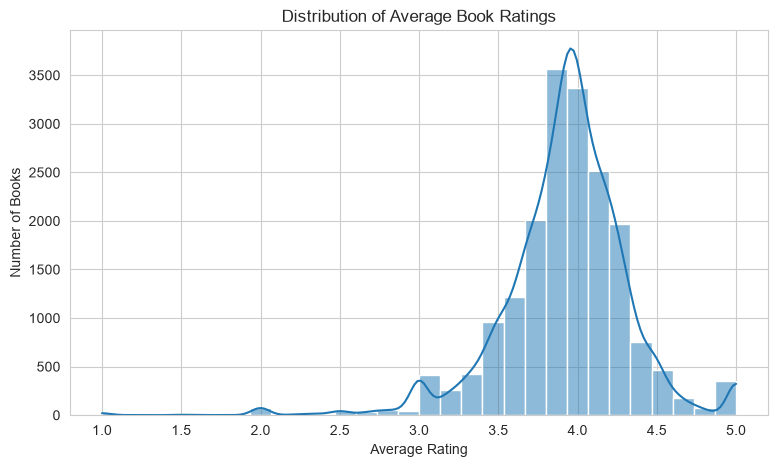

In [160]:
# Histogram of valid average book ratings

plt.figure(figsize=(9, 5))

sns.histplot(
    rating_df["avg_rating"],
    bins=30,
    kde=True
)

plt.title("Distribution of Average Book Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Books")
plt.show()

##### 2.Boxplot of average book ratings

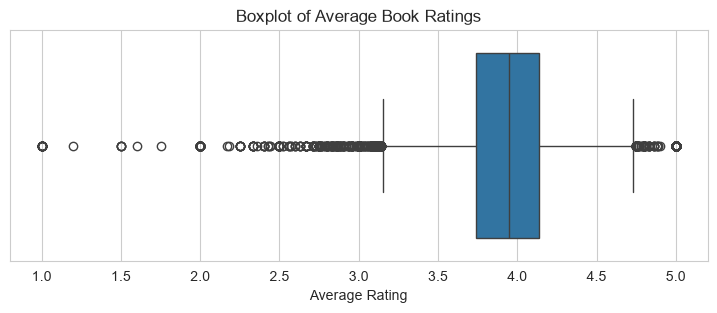

In [161]:
# Boxplot of valid average book ratings

plt.figure(figsize=(9, 3))

sns.boxplot(x=rating_df["avg_rating"])

plt.title("Boxplot of Average Book Ratings")
plt.xlabel("Average Rating")
plt.show()

##### 3.Total ratings by star category

,Star Rating,Total Ratings
0,rated_1,37780854.0
1,rated_2,77032351.0
2,rated_3,261602301.0
3,rated_4,462839961.0
4,rated_5,607445032.0


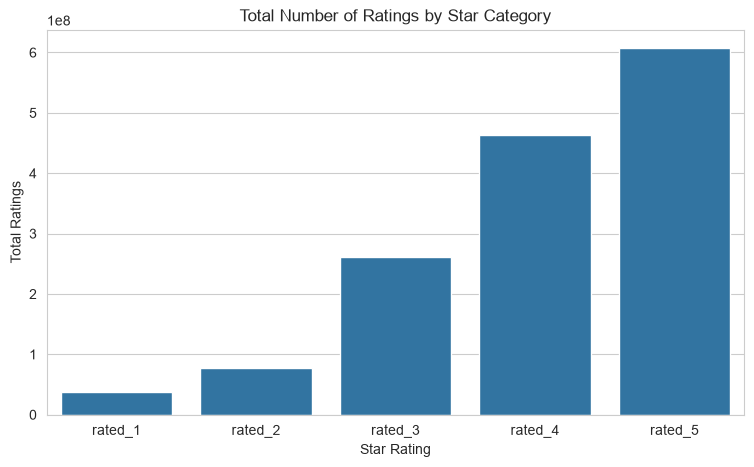

In [162]:
# Total counts for each individual star-rating category
rating_columns = [
    col for col in
    ["rated_1", "rated_2", "rated_3", "rated_4", "rated_5"]
    if col in df.columns
]

if rating_columns:
    rating_totals = (
        df[rating_columns]
        .sum()
        .rename_axis("Star Rating")
        .reset_index(name="Total Ratings")
    )

    display(rating_totals)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=rating_totals,
        x="Star Rating",
        y="Total Ratings"
    )

    plt.title("Total Number of Ratings by Star Category")
    plt.xlabel("Star Rating")
    plt.ylabel("Total Ratings")
    plt.show()

#### Step 7: Univariate analysis- book length

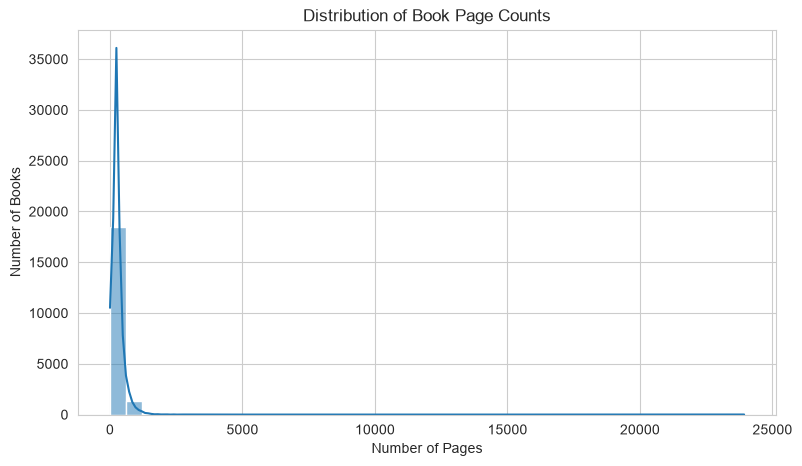

In [163]:
# Histogram of book page counts
if "num_pages" in df.columns:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        df["num_pages"].dropna(),
        bins=40,
        kde=True
    )

    plt.title("Distribution of Book Page Counts")
    plt.xlabel("Number of Pages")
    plt.ylabel("Number of Books")
    plt.show()

#### Step 8: Univariate analysis - reader engagement

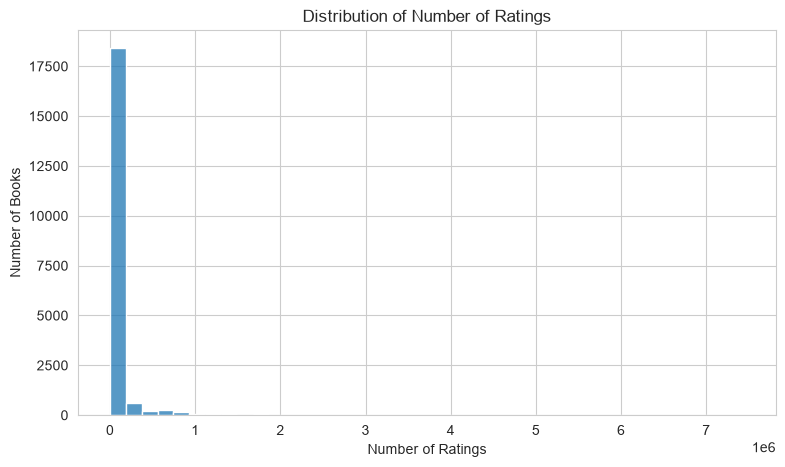

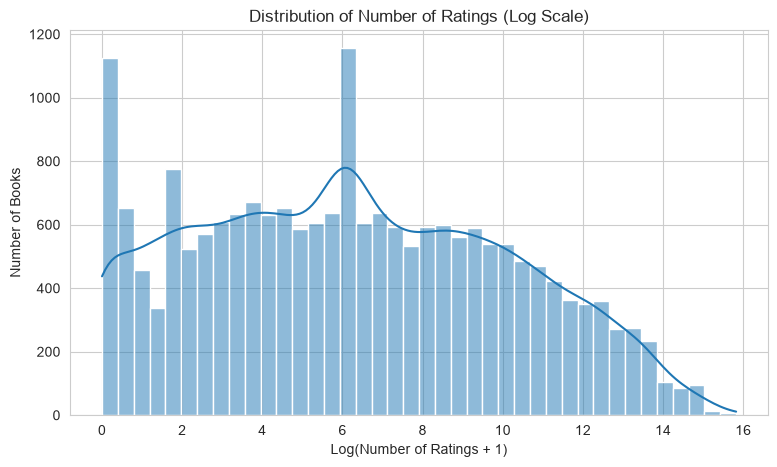

In [164]:
# Distribution of number of ratings
if "num_ratings" in df.columns:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        df["num_ratings"].dropna(),
        bins=40
    )

    plt.title("Distribution of Number of Ratings")
    plt.xlabel("Number of Ratings")
    plt.ylabel("Number of Books")
    plt.show()

    # Log-transformed distribution
    plt.figure(figsize=(9, 5))

    sns.histplot(
        np.log1p(df["num_ratings"].dropna()),
        bins=40,
        kde=True
    )

    plt.title("Distribution of Number of Ratings (Log Scale)")
    plt.xlabel("Log(Number of Ratings + 1)")
    plt.ylabel("Number of Books")
    plt.show()

#### Step 9: Popularity analysis

##### 1. Display the top 15 popular books

In [165]:
# Identify the 15 most popular books based on number of ratings
if {"title", "num_ratings"}.issubset(df.columns):

    popular_books = df.nlargest(15, "num_ratings")[
        [
            col for col in [
                "title", "author", "avg_rating",
                "num_ratings", "num_reviews"
            ]
            if col in df.columns
        ]
    ]

    display(popular_books)

,title,author,avg_rating,num_ratings,num_reviews
15822,Harry Potter y la piedra filosofal,"J.K. Rowling,Alicia Dellepiane Rawson,Dolores ...",4.48,7444102.0,117992.0
15825,Harry Potter à l'école des sorciers,"J.K. Rowling,Jean-François Ménard",4.48,7444102.0,117992.0
15834,Harrius Potter et Philosophi Lapis,"J.K. Rowling,Peter Needham",4.48,7444102.0,117992.0
4245,Harry Potter and the Philosopher's Stone,J.K. Rowling,4.48,7437005.0,117859.0
3350,Harry Potter y la piedra filosofal,J.K. Rowling,4.48,7436916.0,117857.0
3351,Harry Potter Y La Piedra Filosofal,J.K. Rowling,4.48,7436916.0,117857.0
2,Harry Potter and the Sorcerer's Stone,"J.K. Rowling,Mary Grandpré",4.48,7434783.0,117823.0
11985,Twilight,Stephenie Meyer,3.61,5173079.0,106718.0
2648,To Kill a Mockingbird,Harper Lee,4.28,4712812.0,94358.0
2654,To Kill a Mockingbird,Harper Lee,4.28,4712812.0,94358.0


##### 2.Visualise the top 15 popular books.

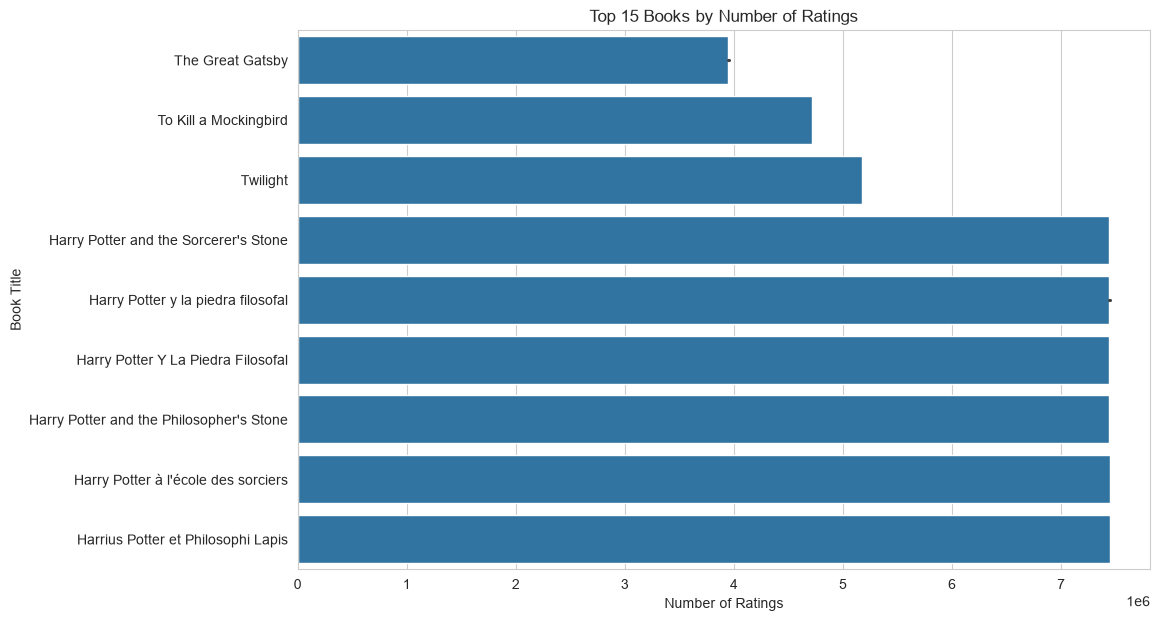

In [166]:
# Bar chart of the top 15 books by number of ratings
if {"title", "num_ratings"}.issubset(df.columns):

    plot_data = (
        df.nlargest(15, "num_ratings")
        .sort_values("num_ratings")
    )

    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=plot_data,
        x="num_ratings",
        y="title"
    )

    plt.title("Top 15 Books by Number of Ratings")
    plt.xlabel("Number of Ratings")
    plt.ylabel("Book Title")
    plt.show()

#### Step 10: Genre analysis

In [167]:
from collections import Counter

##### 1. Count every genre label across all books

In [168]:
# Count every genre label across all books
if "genre_list" in df.columns:

    genre_counts = Counter(
        genre
        for genre_list in df["genre_list"]
        for genre in genre_list
    )

    genre_counts_df = pd.DataFrame(
        genre_counts.items(),
        columns=["Genre", "Book_Count"]
    ).sort_values("Book_Count", ascending=False)

    print("Number of distinct genre labels:", len(genre_counts_df))

    display(genre_counts_df.head(15))

Number of distinct genre labels: 840


,Genre,Book_Count
2,Fiction,8121
51,Literature,4964
28,Nonfiction,4886
8,Classics,4788
18,Novels,3579
33,Historical,2934
0,Fantasy,2906
37,Cultural,2669
78,Historical Fiction,2352
30,History,2176


##### 2. Plot the 15 most common genre labels

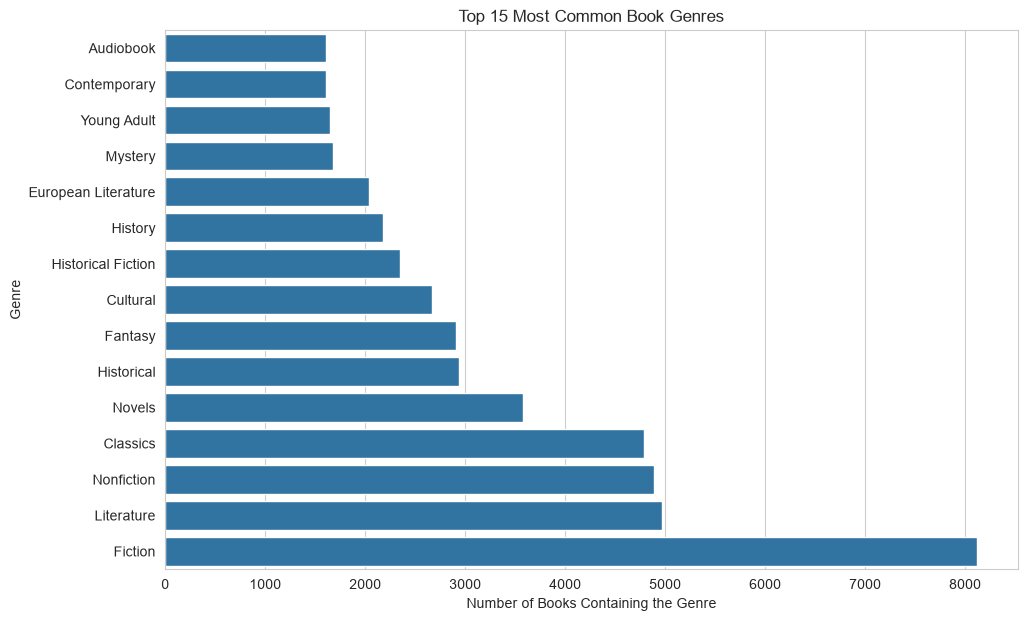

In [169]:
# Plot the 15 most common genre labels
if "genre_list" in df.columns and not genre_counts_df.empty:

    top_genres = genre_counts_df.head(15).sort_values("Book_Count")

    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=top_genres,
        x="Book_Count",
        y="Genre"
    )

    plt.title("Top 15 Most Common Book Genres")
    plt.xlabel("Number of Books Containing the Genre")
    plt.ylabel("Genre")
    plt.show()

##### 3. Compare average ratings by primary genre

In [170]:
genre_rating = (
    rating_df[rating_df["primary_genre"] != "Unknown"]
    .groupby("primary_genre")
    .agg(
        total_books=("primary_genre", "size"),
        average_rating=("avg_rating", "mean")
    )
    .reset_index()
)

genre_rating = genre_rating[
    genre_rating["total_books"] >= 30
]

genre_rating = genre_rating.sort_values(
    "average_rating",
    ascending=False
)

display(genre_rating.head(15))

,primary_genre,total_books,average_rating
19,Christian,112,4.225536
20,Christian Fiction,43,4.193023
5,Animals,53,4.139623
96,Poetry,355,4.108000
114,Sequential Art,357,4.070700
119,Spirituality,96,4.057604
132,Writing,55,4.056000
36,Design,58,4.051897
83,Music,125,4.049200
10,Art,174,4.033333


##### 4. Plot the 15 highest-rated primary genres

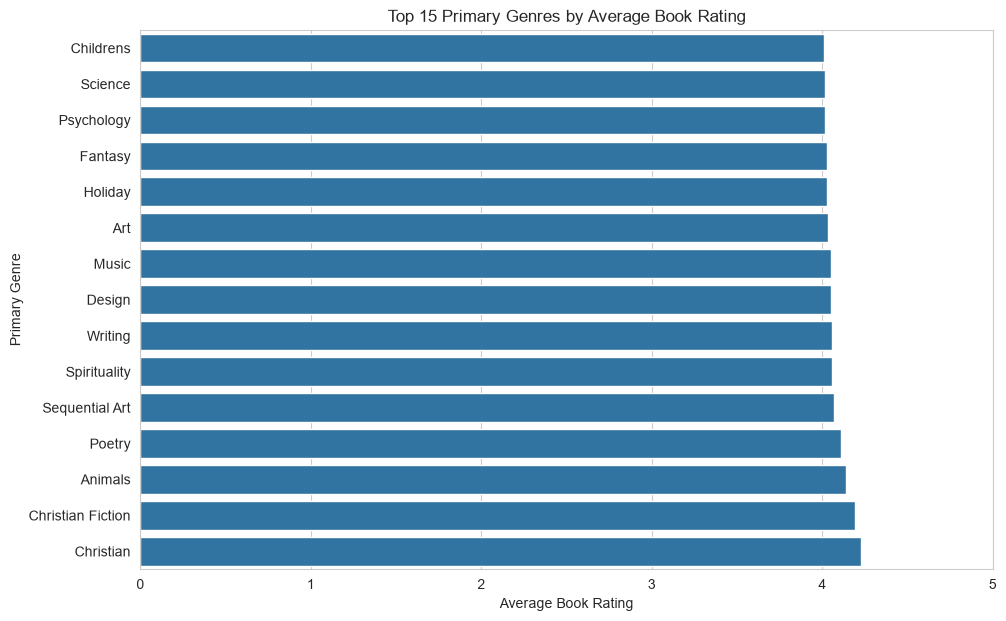

In [171]:
# Plot the 15 highest-rated primary genres
if "genre_rating" in globals() and not genre_rating.empty:

    plot_data = genre_rating.head(15).sort_values("average_rating")

    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=plot_data,
        x="average_rating",
        y="primary_genre"
    )

    plt.title("Top 15 Primary Genres by Average Book Rating")
    plt.xlabel("Average Book Rating")
    plt.ylabel("Primary Genre")
    plt.xlim(0, 5)
    plt.show()

##### 5.Compare reader attention by primary genre

In [172]:
# Compare reader attention by primary genre
if {"primary_genre", "num_ratings"}.issubset(df.columns):

    genre_popularity = (
        df[df["primary_genre"] != "Unknown"]
        .groupby("primary_genre")
        .agg(
            total_books=("primary_genre", "size"),
            median_ratings=("num_ratings", "median")
        )
        .reset_index()
    )

    # Keep genres with at least 30 books
    genre_popularity = genre_popularity[
        genre_popularity["total_books"] >= 30
    ]

    genre_popularity = genre_popularity.sort_values(
        "median_ratings",
        ascending=False
    )

    display(genre_popularity.head(15))

,primary_genre,total_books,median_ratings
22,Classics,1501,140568.0
130,Womens Fiction,75,40022.0
65,Horror,294,18666.0
47,Fantasy,915,9938.0
49,Fiction,2656,9885.5
62,Historical,379,8648.0
133,Young Adult,115,8237.0
124,Thriller,30,7924.5
111,Science Fiction,354,7412.5
84,Mystery,495,5909.0


##### 6. Plot the 15 most popular primary genres

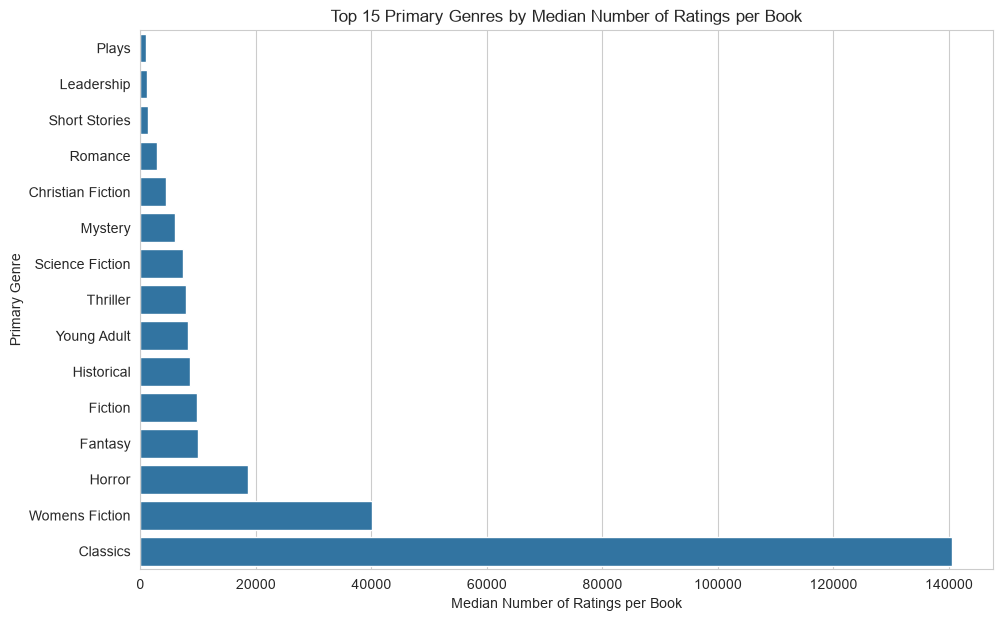

In [173]:
# Plot the 15 genres with the highest median ratings per book
if "genre_popularity" in globals() and not genre_popularity.empty:

    plot_data = genre_popularity.head(15).sort_values(
        "median_ratings"
    )

    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=plot_data,
        x="median_ratings",
        y="primary_genre"
    )

    plt.title("Top 15 Primary Genres by Median Number of Ratings per Book")
    plt.xlabel("Median Number of Ratings per Book")
    plt.ylabel("Primary Genre")
    plt.show()

##### 7.Create a combined genre summary table

In [174]:
# Create a combined genre summary table

# Overall book counts and reader attention
genre_summary = (
    df[df["primary_genre"] != "Unknown"]
    .groupby("primary_genre")
    .agg(
        total_books=("bookId", "count"),
        median_ratings=("num_ratings", "median"),
        average_reviews=("num_reviews", "mean")
    )
    .reset_index()
)

# Calculate average ratings using only books with valid ratings
valid_genre_ratings = (
    rating_df[rating_df["primary_genre"] != "Unknown"]
    .groupby("primary_genre")
    .agg(
        average_rating=("avg_rating", "mean")
    )
    .reset_index()
)

# Combine both summaries
genre_summary = genre_summary.merge(
    valid_genre_ratings,
    on="primary_genre",
    how="left"
)

# Keep genres with at least 30 books
genre_summary = genre_summary[
    genre_summary["total_books"] >= 30
]

display(
    genre_summary
    .sort_values("total_books", ascending=False)
    .head(15)
)

,primary_genre,total_books,median_ratings,average_reviews,average_rating
49,Fiction,2656,9885.5,3693.688253,3.850267
22,Classics,1501,140568.0,10525.595603,3.939960
87,Nonfiction,1474,821.0,1851.837178,3.927517
47,Fantasy,915,9938.0,4491.112568,4.025661
63,History,604,259.5,483.354305,3.947616
18,Childrens,510,323.5,655.201961,4.009922
84,Mystery,495,5909.0,1361.763636,3.920505
94,Philosophy,395,793.0,459.982278,3.937570
15,Biography,384,193.0,148.255208,3.916432
62,Historical,379,8648.0,2846.329815,3.968259


#### Step 11: Author analysis

##### 1. Top 15 authors by number of books

In [175]:
# Count the number of books for each main author
if "main_author" in df.columns:

    author_counts = (
        df[df["main_author"] != "Unknown"]["main_author"]
        .value_counts()
        .head(15)
        .rename_axis("Author")
        .reset_index(name="Book_Count")
    )

    display(author_counts)

,Author,Book_Count
0,Stephen King,140
1,P.G. Wodehouse,115
2,Piers Anthony,110
3,William Shakespeare,107
4,J.R.R. Tolkien,105
5,Agatha Christie,80
6,Dick Francis,67
7,Charles Dickens,66
8,David Burnie,65
9,Fyodor Dostoyevsky,62


##### 2. Visualise the top 15 authors

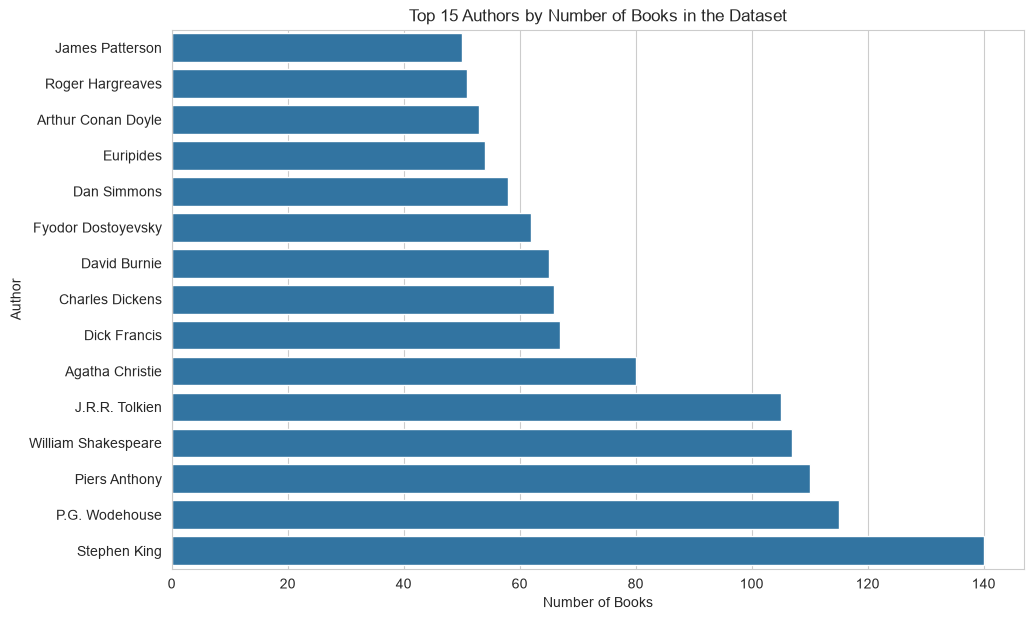

In [176]:
# Plot the top 15 authors by number of books
if "main_author" in df.columns and not author_counts.empty:

    author_plot = author_counts.sort_values("Book_Count")

    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=author_plot,
        x="Book_Count",
        y="Author"
    )

    plt.title("Top 15 Authors by Number of Books in the Dataset")
    plt.xlabel("Number of Books")
    plt.ylabel("Author")
    plt.show()

##### 3.Average ratings by author

In [177]:
# Calculate average ratings for authors with at least 5 rated books

if {"main_author", "avg_rating"}.issubset(rating_df.columns):

    author_ratings = (
        rating_df[rating_df["main_author"] != "Unknown"]
        .groupby("main_author")
        .agg(
            total_books=("main_author", "size"),
            average_rating=("avg_rating", "mean")
        )
        .reset_index()
    )

    author_ratings = author_ratings[
        author_ratings["total_books"] >= 5
    ]

    author_ratings = author_ratings.sort_values(
        "average_rating",
        ascending=False
    )

    display(author_ratings.head(15))

,main_author,total_books,average_rating
2640,Gregory Nagy,16,4.645625
2556,Giles Reed,32,4.590312
2843,Hiromu Arakawa,8,4.557500
2997,J.K. Rowling,27,4.522963
2431,Gary Russell,7,4.482857
841,Brian Sibley,11,4.476364
3892,Jude Fisher,9,4.456667
4230,Kyoko Hikawa,16,4.455625
4009,Karen Kingsbury,13,4.423846
1105,Charles R. Swindoll,6,4.420000


#### Step 12: Relationships between variables.

##### 1. Number of ratings vs average book rating

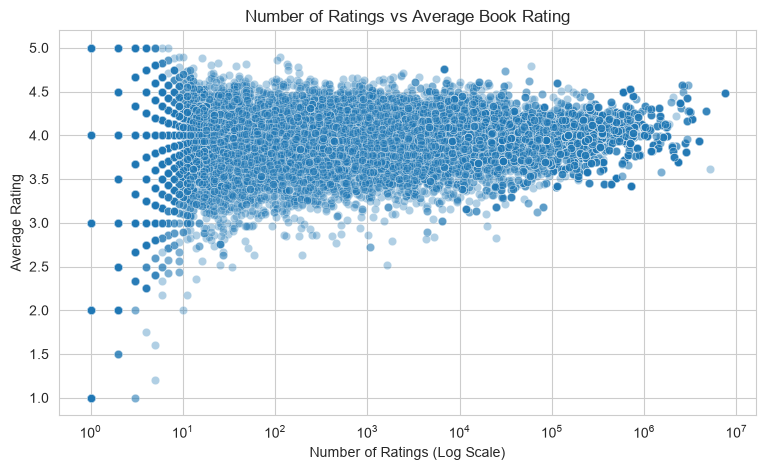

In [178]:
# Number of ratings compared with average rating

if {"num_ratings", "avg_rating"}.issubset(rating_df.columns):

    plt.figure(figsize=(9, 5))

    sns.scatterplot(
        data=rating_df,
        x="num_ratings",
        y="avg_rating",
        alpha=0.35
    )

    plt.xscale("log")
    plt.title("Number of Ratings vs Average Book Rating")
    plt.xlabel("Number of Ratings (Log Scale)")
    plt.ylabel("Average Rating")
    plt.show()

##### 2.Number of pages vs average book rating

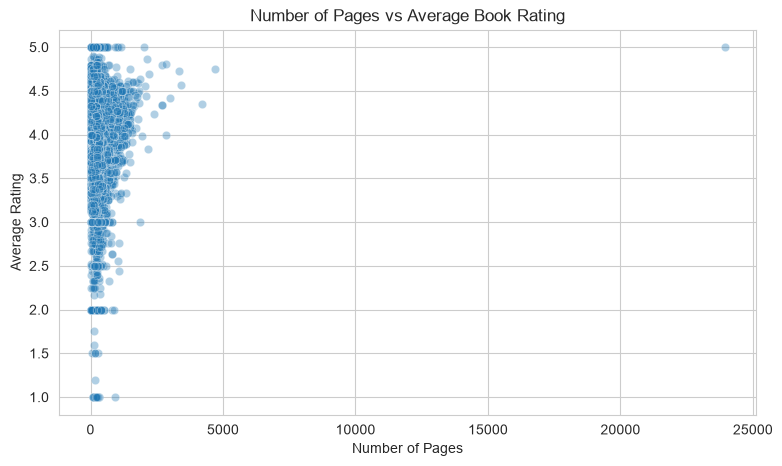

In [179]:
# Number of pages compared with average rating

if {"num_pages", "avg_rating"}.issubset(rating_df.columns):

    plt.figure(figsize=(9, 5))

    sns.scatterplot(
        data=rating_df,
        x="num_pages",
        y="avg_rating",
        alpha=0.35
    )

    plt.title("Number of Pages vs Average Book Rating")
    plt.xlabel("Number of Pages")
    plt.ylabel("Average Rating")
    plt.show()

##### 3. Number of reviews vs number of ratings

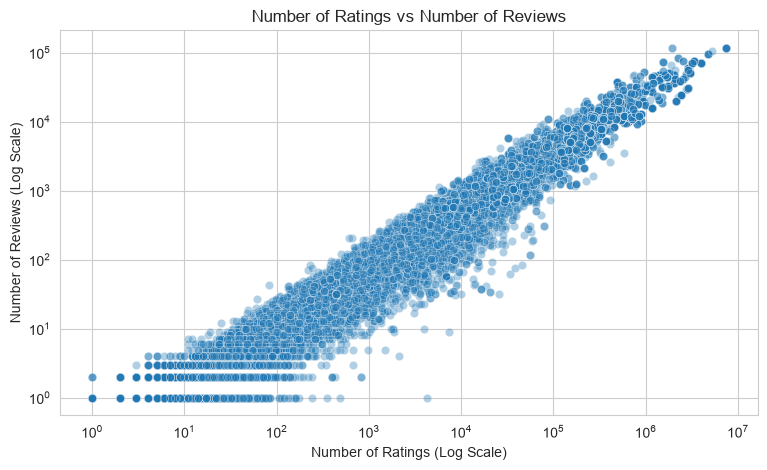

In [180]:
# Number of reviews compared with number of ratings
if {"num_reviews", "num_ratings"}.issubset(df.columns):

    plt.figure(figsize=(9, 5))

    sns.scatterplot(
        data=df,
        x="num_ratings",
        y="num_reviews",
        alpha=0.35
    )

    plt.xscale("log")
    plt.yscale("log")

    plt.title("Number of Ratings vs Number of Reviews")
    plt.xlabel("Number of Ratings (Log Scale)")
    plt.ylabel("Number of Reviews (Log Scale)")
    plt.show()

#### Step 13: Correlation analysis

##### 1. Calculate correlations between numerical variables

In [212]:
# Calculate correlations between numerical variables
correlation_data = rating_df.select_dtypes(include=np.number)

correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(2))

,bookId,num_pages,num_ratings,num_reviews,avg_rating,rated_1,rated_2,rated_3,rated_4,rated_5,genre_count
bookId,1.00,-0.00,-0.06,-0.06,0.01,-0.06,-0.06,-0.06,-0.06,-0.05,0.04
num_pages,-0.00,1.00,0.04,0.05,0.10,0.03,0.02,0.03,0.03,0.04,0.15
num_ratings,-0.06,0.04,1.00,0.93,0.08,0.86,0.88,0.94,0.99,0.97,0.19
num_reviews,-0.06,0.05,0.93,1.00,0.08,0.81,0.84,0.88,0.93,0.87,0.24
avg_rating,0.01,0.10,0.08,0.08,1.00,0.02,0.01,0.04,0.07,0.09,0.10
rated_1,-0.06,0.03,0.86,0.81,0.02,1.00,0.96,0.92,0.86,0.75,0.17
rated_2,-0.06,0.02,0.88,0.84,0.01,0.96,1.00,0.98,0.91,0.73,0.20
rated_3,-0.06,0.03,0.94,0.88,0.04,0.92,0.98,1.00,0.97,0.82,0.21
rated_4,-0.06,0.03,0.99,0.93,0.07,0.86,0.91,0.97,1.00,0.92,0.20
rated_5,-0.05,0.04,0.97,0.87,0.09,0.75,0.73,0.82,0.92,1.00,0.15


##### 2. Visualise the correlation matrix using a heatmap

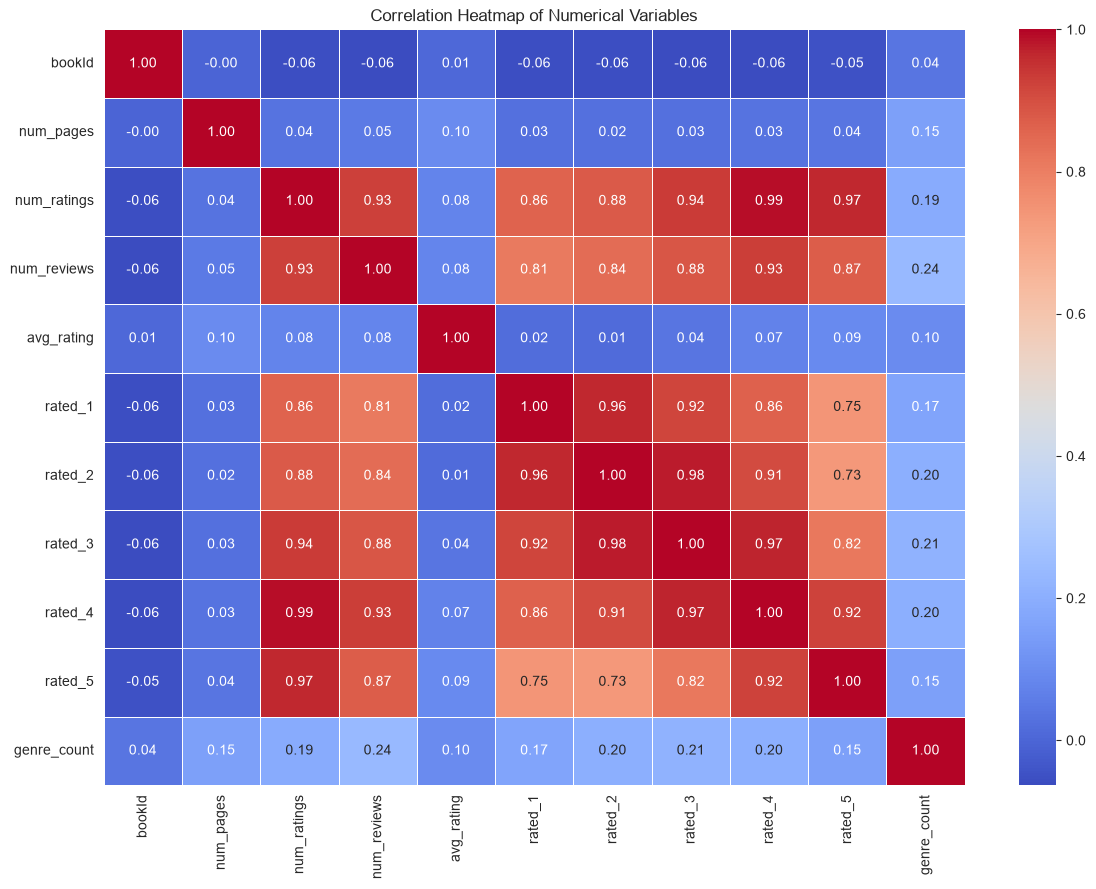

In [213]:
# Visualise the correlation matrix
if not correlation_matrix.empty:

    plt.figure(figsize=(12, 9))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Heatmap of Numerical Variables")
    plt.tight_layout()
    plt.show()

In [214]:
# Check books with zero average ratings
zero_rating_books = df[df["avg_rating"] == 0]

print("Books with zero average rating:", len(zero_rating_books))

# Check their number of ratings
display(
    zero_rating_books[
        ["title", "avg_rating", "num_ratings", "num_reviews"]
    ].head(10)
)

Books with zero average rating: 1124


,title,avg_rating,num_ratings,num_reviews
520,English-Cayuga/Cayuga-English Dictionary,0.0,0.0,1.0
550,Simple Storage Solutions,0.0,0.0,0.0
560,"The Colored Gentleman, a Product of Modern Civ...",0.0,0.0,0.0
571,1000 Cornish Place Names (Tor Mark Paperbacks,0.0,0.0,0.0
576,Paul Huf: record covers,0.0,0.0,0.0
609,The Faking of the Vice-President: A Guide to B...,0.0,0.0,0.0
612,Decadent health: A survival guide for elegant ...,0.0,0.0,0.0
711,Swiss Design 2004,0.0,0.0,0.0
712,Swiss Design 2003: Desir Design,0.0,0.0,0.0
716,Swiss Book: Visual Designs of Swiss Hospitality,0.0,0.0,0.0


In [215]:
# Compare zero average ratings with the number of ratings
print(
    "Zero average rating and zero ratings:",
    len(df[(df["avg_rating"] == 0) & (df["num_ratings"] == 0)])
)

print(
    "Zero average rating but ratings available:",
    len(df[(df["avg_rating"] == 0) & (df["num_ratings"] > 0)])
)

Zero average rating and zero ratings: 1124
Zero average rating but ratings available: 0


#### Genre Analysis

In [185]:
df[['genres', 'genre_list', 'primary_genre']].head()

,genres,genre_list,primary_genre
0,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",Fantasy
1,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",Fantasy
2,"Art,Biography,Business,Children's,Christian,Cl...","[Goodreads' Transgender Books page, Fantasy, F...",Goodreads' Transgender Books page
3,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",Fantasy
4,"Art,Biography,Business,Children's,Christian,Cl...","[Fantasy, Young Adult, Fiction, Magic, Childre...",Fantasy


In [186]:
print("Books with unknown genres:",
      (df['primary_genre'] == 'Unknown').sum())

print("Unique primary genres:",
      df['primary_genre'].nunique())

Books with unknown genres: 5055
Unique primary genres: 135


In [187]:
from collections import Counter

genre_counts = Counter(
    genre
    for genres in df['genre_list']
    for genre in genres
)

genre_counts_df = pd.DataFrame(
    genre_counts.items(),
    columns=['Genre', 'Book_Count']
)

genre_counts_df = genre_counts_df.sort_values(
    by='Book_Count',
    ascending=False
)

genre_counts_df.head(15)

,Genre,Book_Count
2,Fiction,8121
51,Literature,4964
28,Nonfiction,4886
8,Classics,4788
18,Novels,3579
33,Historical,2934
0,Fantasy,2906
37,Cultural,2669
78,Historical Fiction,2352
30,History,2176


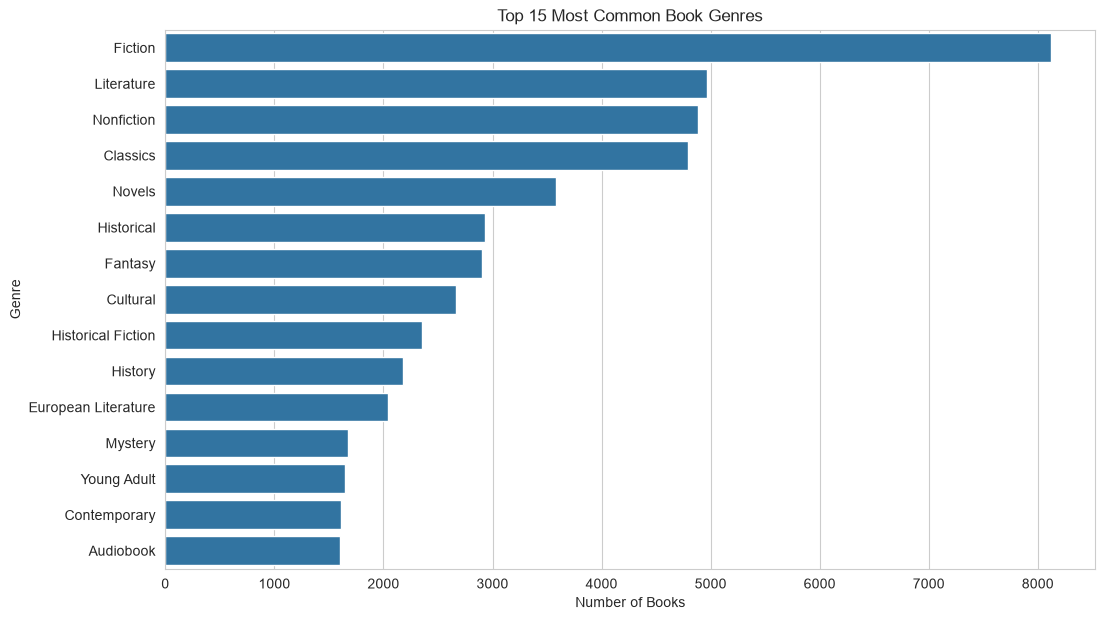

In [188]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_counts_df.head(15),
    x='Book_Count',
    y='Genre'
)

plt.title('Top 15 Most Common Book Genres')
plt.xlabel('Number of Books')
plt.ylabel('Genre')

plt.show()

In [189]:
genre_rating = (
    rating_df[rating_df['primary_genre'] != 'Unknown']
    .groupby('primary_genre')
    .agg(
        total_books=('bookId', 'count'),
        average_rating=('avg_rating', 'mean')
    )
    .reset_index()
)

genre_rating = genre_rating[
    genre_rating['total_books'] >= 30
]

genre_rating = genre_rating.sort_values(
    by='average_rating',
    ascending=False
)

genre_rating.head(15)

,primary_genre,total_books,average_rating
19,Christian,112,4.225536
20,Christian Fiction,43,4.193023
5,Animals,53,4.139623
96,Poetry,355,4.108000
114,Sequential Art,357,4.070700
119,Spirituality,96,4.057604
132,Writing,55,4.056000
36,Design,58,4.051897
83,Music,125,4.049200
10,Art,174,4.033333


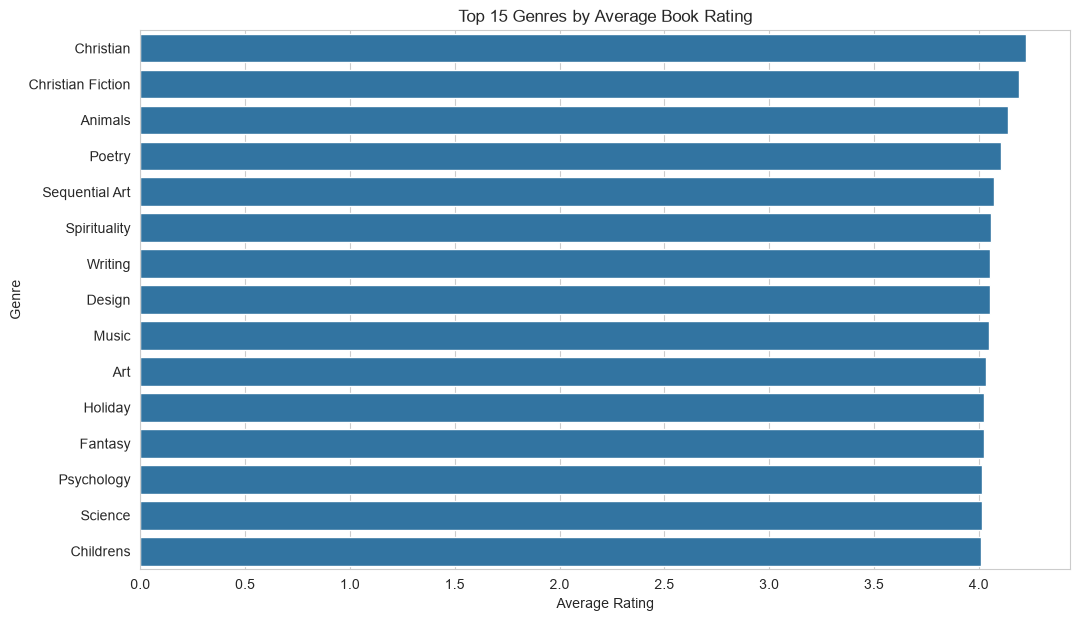

In [190]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_rating.head(15),
    x='average_rating',
    y='primary_genre'
)

plt.title('Top 15 Genres by Average Book Rating')
plt.xlabel('Average Rating')
plt.ylabel('Genre')

plt.show()

In [191]:
genre_popularity = (
    df[df['primary_genre'] != 'Unknown']
    .groupby('primary_genre')
    .agg(
        total_books=('bookId', 'count'),
        median_ratings=('num_ratings', 'median')
    )
    .reset_index()
)

genre_popularity = genre_popularity[
    genre_popularity['total_books'] >= 30
]

genre_popularity = genre_popularity.sort_values(
    by='median_ratings',
    ascending=False
)

genre_popularity.head(15)

,primary_genre,total_books,median_ratings
22,Classics,1501,140568.0
130,Womens Fiction,75,40022.0
65,Horror,294,18666.0
47,Fantasy,915,9938.0
49,Fiction,2656,9885.5
62,Historical,379,8648.0
133,Young Adult,115,8237.0
124,Thriller,30,7924.5
111,Science Fiction,354,7412.5
84,Mystery,495,5909.0


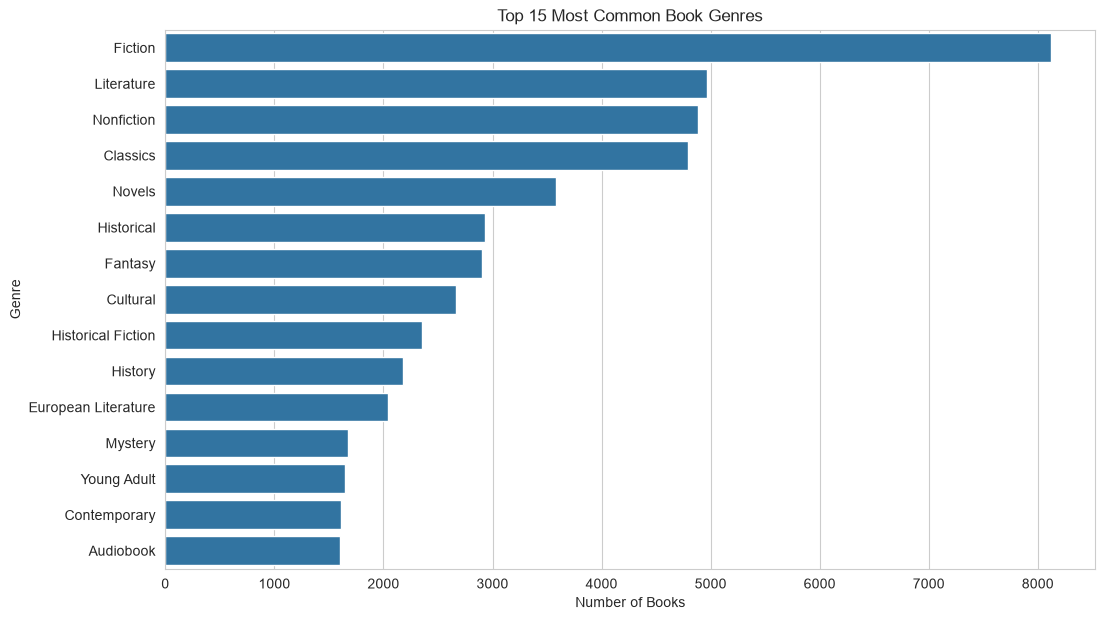

In [192]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_counts_df.head(15),
    x='Book_Count',
    y='Genre'
)

plt.title('Top 15 Most Common Book Genres')
plt.xlabel('Number of Books')
plt.ylabel('Genre')

plt.show()

In [193]:
all_genres = set(g.strip() for row in df['genres'] for g in row.split(','))
print("Unique genres overall:", len(all_genres))

print(df['genres'].nunique(), "unique genre strings")
print(df['genres'].value_counts().head())

Unique genres overall: 843
9697 unique genre strings
genres
Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult               4800
Unknown                                                                                                                                                                                                                                                                                                                                                                                        

In [194]:
print(df['genres'].iloc[0])
print(df['genres'].iloc[1000])

Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Fantasy,Young Adult,Fiction,Fantasy,Magic,Childrens,Adventure,Audiobook,Childrens,Middle Grade,Classics,Science Fiction Fantasy
Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Art,Biography,Business,Children's,Christian,Classics,Comics,Cookb

In [195]:
# Display all column names

print("Columns in the dataset:\n")

for col in df.columns:
    print(col)

Columns in the dataset:

bookId
title
author
description
genres
language
num_pages
num_ratings
num_reviews
avg_rating
rated_1
rated_2
rated_3
rated_4
rated_5
genre_list
genre_count
primary_genre
main_author


In [196]:
# Check data types of all columns

df.dtypes

bookId             int64
title                str
author               str
description          str
genres               str
language             str
num_pages        float64
num_ratings      float64
num_reviews      float64
avg_rating       float64
rated_1          float64
rated_2          float64
rated_3          float64
rated_4          float64
rated_5          float64
genre_list        object
genre_count        int64
primary_genre        str
main_author       object
dtype: object

In [197]:
# Display dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19941 entries, 0 to 19940
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   bookId         19941 non-null  int64  
 1   title          19941 non-null  str    
 2   author         19941 non-null  str    
 3   description    19941 non-null  str    
 4   genres         19941 non-null  str    
 5   language       19941 non-null  str    
 6   num_pages      19941 non-null  float64
 7   num_ratings    19941 non-null  float64
 8   num_reviews    19941 non-null  float64
 9   avg_rating     19941 non-null  float64
 10  rated_1        19941 non-null  float64
 11  rated_2        19941 non-null  float64
 12  rated_3        19941 non-null  float64
 13  rated_4        19941 non-null  float64
 14  rated_5        19941 non-null  float64
 15  genre_list     19941 non-null  object 
 16  genre_count    19941 non-null  int64  
 17  primary_genre  19941 non-null  str    
 18  main_author    19

In [198]:
# Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
['bookId', 'num_pages', 'num_ratings', 'num_reviews', 'avg_rating', 'rated_1', 'rated_2', 'rated_3', 'rated_4', 'rated_5', 'genre_count']


In [199]:
# Identify categorical columns

categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

Categorical Columns:
['title', 'author', 'description', 'genres', 'language', 'genre_list', 'primary_genre', 'main_author']


C:\Users\RACHANA\AppData\Local\Temp\ipykernel_38940\4008030294.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [200]:
# Generate descriptive statistics

df.describe()

,bookId,num_pages,num_ratings,num_reviews,avg_rating,rated_1,rated_2,rated_3,rated_4,rated_5,genre_count
count,19941.000000,19941.000000,1.994100e+04,19941.000000,19941.000000,19941.000000,19941.000000,1.994100e+04,1.994100e+04,1.994100e+04,19941.000000
mean,9998.834863,289.252495,7.238187e+04,2023.433027,3.700443,1894.631864,3863.013440,1.311882e+04,2.321047e+04,3.046211e+04,6.560704
std,5774.933652,295.282735,3.268402e+05,7317.152215,0.986458,9776.141957,16979.065343,5.327327e+04,9.755710e+04,1.626719e+05,5.023824
min,1.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,4997.000000,160.000000,2.200000e+01,2.000000,3.680000,2.000000,7.000000,2.900000e+01,4.400000e+01,4.100000e+01,0.000000
50%,9998.000000,252.000000,4.370000e+02,32.000000,3.930000,17.000000,56.000000,2.420000e+02,3.800000e+02,3.560000e+02,9.000000
75%,15000.000000,356.000000,1.039400e+04,520.000000,4.130000,165.000000,521.000000,2.167000e+03,3.589000e+03,3.478000e+03,11.000000
max,20000.000000,23931.000000,7.444102e+06,117992.000000,5.000000,562807.000000,560978.000000,1.052619e+06,1.696235e+06,4.845445e+06,15.000000


In [201]:
# Summary of categorical features

df.describe(include='object').T

C:\Users\RACHANA\AppData\Local\Temp\ipykernel_38940\2261844554.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
title,19941,16904,Unknown,557
author,19941,11899,Unknown,565
description,19941,16320,Unknown,2674
genres,19941,9697,"Art,Biography,Business,Children's,Christian,Cl...",4800
language,19941,23,English,16209
genre_list,19941,9631,[],5055
primary_genre,19941,135,Unknown,5055
main_author,19941,8481,Unknown,577


In [202]:
# Count missing values in each column

missing_values = df.isnull().sum()

missing_values

bookId           0
title            0
author           0
description      0
genres           0
language         0
num_pages        0
num_ratings      0
num_reviews      0
avg_rating       0
rated_1          0
rated_2          0
rated_3          0
rated_4          0
rated_5          0
genre_list       0
genre_count      0
primary_genre    0
main_author      0
dtype: int64

In [203]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

bookId           0.0
title            0.0
author           0.0
description      0.0
genres           0.0
language         0.0
num_pages        0.0
num_ratings      0.0
num_reviews      0.0
avg_rating       0.0
rated_1          0.0
rated_2          0.0
rated_3          0.0
rated_4          0.0
rated_5          0.0
genre_list       0.0
genre_count      0.0
primary_genre    0.0
main_author      0.0
dtype: float64

In [204]:
# Check duplicate records

print("Total Duplicate Rows:", df.astype(str).duplicated().sum())

Total Duplicate Rows: 0


#### Boxplot

#### Distribution of Number of Pages

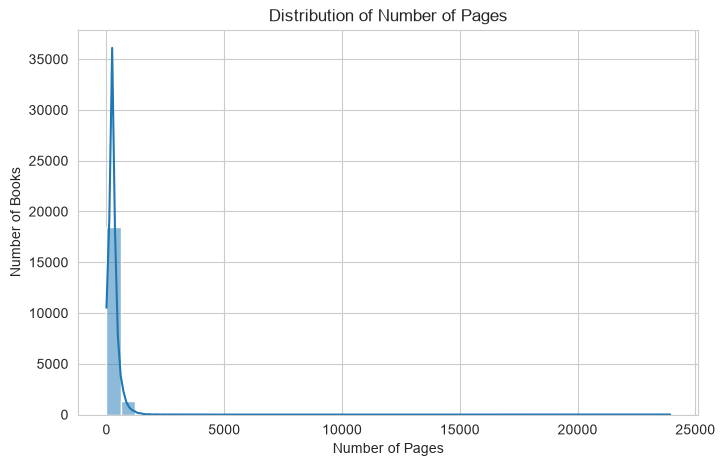

In [205]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='num_pages', bins=40, kde=True)

plt.title('Distribution of Number of Pages')
plt.xlabel('Number of Pages')
plt.ylabel('Number of Books')

plt.show()

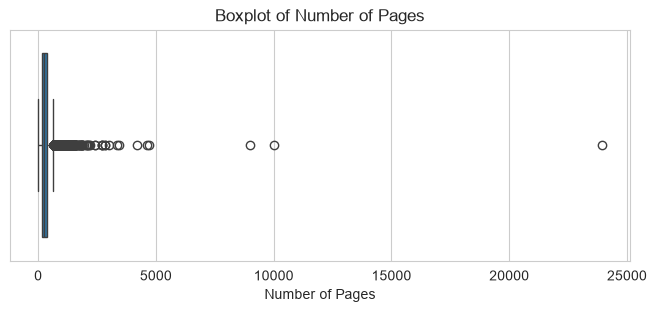

In [206]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df['num_pages'])

plt.title('Boxplot of Number of Pages')
plt.xlabel('Number of Pages')

plt.show()

#### Distribution of Number of Ratings

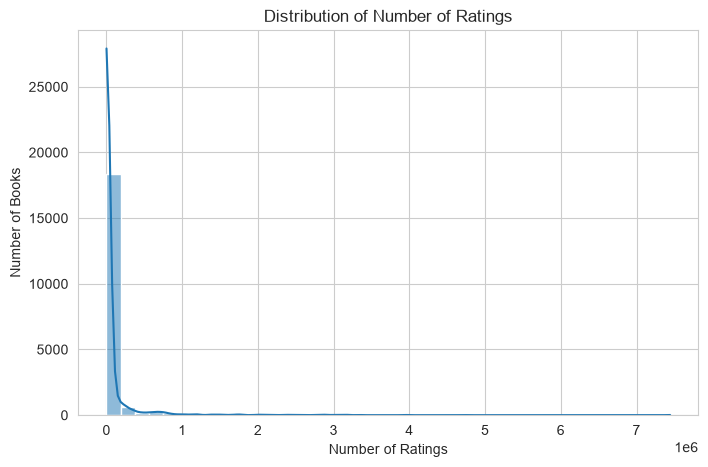

In [207]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='num_ratings', bins=40, kde=True)

plt.title('Distribution of Number of Ratings')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Books')

plt.show()

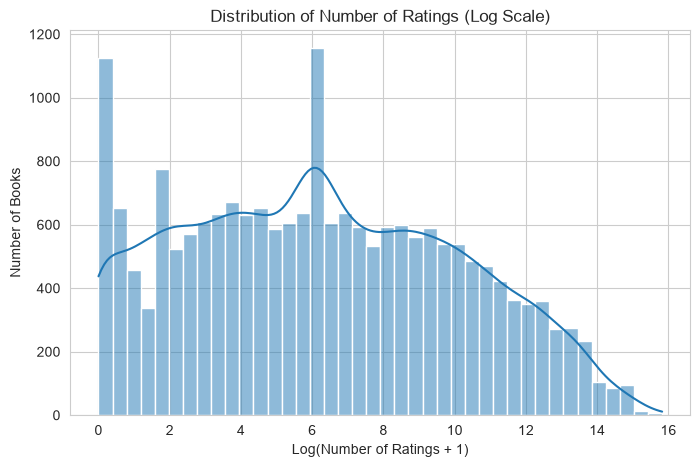

In [208]:
plt.figure(figsize=(8, 5))

sns.histplot(np.log1p(df['num_ratings'].dropna()), bins=40, kde=True)

plt.title('Distribution of Number of Ratings (Log Scale)')
plt.xlabel('Log(Number of Ratings + 1)')
plt.ylabel('Number of Books')

plt.show()

#### Distribution of number of reviews.

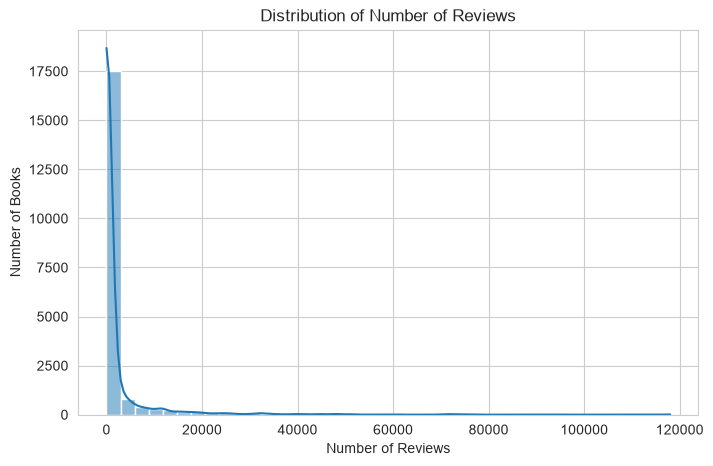

In [209]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='num_reviews', bins=40, kde=True)

plt.title('Distribution of Number of Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Number of Books')

plt.show()

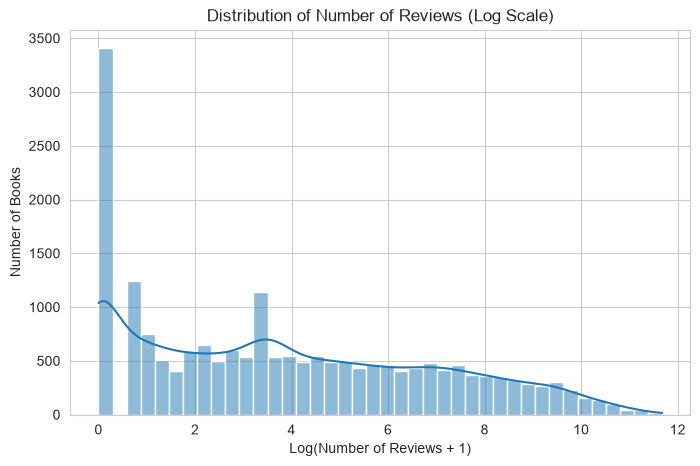

In [210]:
plt.figure(figsize=(8, 5))

sns.histplot(np.log1p(df['num_reviews'].dropna()), bins=40, kde=True)

plt.title('Distribution of Number of Reviews (Log Scale)')
plt.xlabel('Log(Number of Reviews + 1)')
plt.ylabel('Number of Books')

plt.show()

#### Distribution of Individual Star Ratings

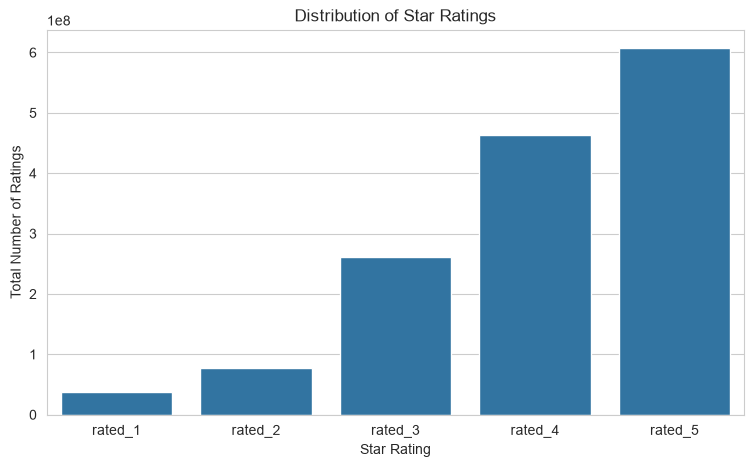

In [211]:
# Calculate total ratings for each star category

rating_columns = ['rated_1', 'rated_2', 'rated_3', 'rated_4', 'rated_5']

rating_totals = df[rating_columns].sum()

plt.figure(figsize=(9, 5))

sns.barplot(x=rating_totals.index, y=rating_totals.values)

plt.title('Distribution of Star Ratings')
plt.xlabel('Star Rating')
plt.ylabel('Total Number of Ratings')

plt.show()

In [216]:
# Step 15: Save the EDA dataset

import os

# Define the output folder and file path
output_dir = "../Data"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "Goodreads Books EDA.csv")

# Save the dataset with EDA features
df.to_csv(output_path, index=False)

print("EDA dataset saved successfully!")
print("File location:", os.path.abspath(output_path))
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

EDA dataset saved successfully!
File location: C:\Users\RACHANA\OneDrive\Desktop\BookScope\Data\Goodreads Books EDA.csv
Total rows: 19941
Total columns: 19
